# 02 - Data Understanding and Cleaning

**Question:** what is in the two PLC recordings, what is wrong with them, and what do the signals mean?

| Part | Content | Source |
|---|---|---|
| 1 | Beckhoff quality check and cleaning | team notebook `01_beckhoff_quality_check` (original code) |
| 2 | Siemens quality check and cleaning | team notebook `01_siemens_quality_check` (original code) |
| 3 | The loader used by the later notebooks, checked against Parts 1-2 | check cell |
| 4 | Logging resolution: detection limit and sync tolerance (figure `time_base`) | team v1 analysis, steps 2.1 and 2.3 |
| 5 | What the signals mean - tested from behaviour | v1 step 2.4, extension |
| 6 | Start of production | v1 step 2.5 |

**Rule:** the raw data is never changed. Outputs: `data/processed/02_data.pkl` (cleaned data, signal dictionary,
logging statistics) for notebook 03 and the figure `reports/figures/time_base.png`.

## Setup

Imports, parameters (the same values as `config.yaml`) and the hand-over of results between the notebooks (`data/processed/`, run the notebooks in order 01-06).

In [1]:
from io import StringIO
from pathlib import Path

from IPython.display import Image, display
import numpy as np
import pandas as pd
from dataclasses import dataclass, field
import re
from scipy import stats as sps
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score, average_precision_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from itertools import combinations
import dataclasses
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch

%matplotlib inline
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

In [2]:
# Parameters - the same values as config.yaml
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = {'paths': {'raw_siemens': 'data/raw/Beispieldatensatz Siemens S7 SPS.csv',
           'raw_beckhoff': 'data/raw/Beispieldatensatz Beckhoff SPS.csv',
           'variable_file': 'data/raw/Variablenerklärung.xlsx',
           'reports_dir': 'reports',
           'figures_dir': 'reports/figures'},
 'timebase': {'gap_report_s': 0.5,
              'gap_cooccur_tolerance_s': 0.2,
              'resample_grids_ms': [20, 50, 76, 93, 100, 200, 500]},
 'phases': {'production_start_signal': 'E200.0',
            'curtain_signal': 'A201.0',
            'curtain_signal_beckhoff': 'VG.safeCurtainShort',
            'hmi_run_signal': 'Visual.start',
            'pallet_request_signals': ['WH.desiredPalletX', 'WH.desiredPalletY'],
            'drilling_cycle_register': 'MW22'},
 'rule': {'tukey_k': 3.0,
          'min_activations': 5,
          'min_excess_s': 'auto',
          'sweep_k': [1.5, 3.0],
          'sweep_min_excess_s': [1.0, 1.5, 1.84, 2.0, 2.5, 3.0, 4.0, 5.0],
          'sweep_merge_gap_s': [0.0, 1.0, 2.0, 5.0, 10.0],
          'merge_gap_s': 0.0},
 'ml': {'seeds': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
        'contamination_sweep': [0.01, 0.02, 0.05, 0.1],
        'kmeans_k': [2, 3, 4, 5, 6, 7, 8],
        'top_k': 10},
 'performance': {'bootstrap_resamples': 5000, 'bootstrap_seed': 42}}
cfg["paths"] = {k: ROOT / v for k, v in cfg["paths"].items()}
PROCESSED = ROOT / "data" / "processed"        # prepared data handed from one notebook to the next
FIGURES = cfg["paths"]["figures_dir"]          # reports/figures

In [3]:
def save_stage(name, results):
    """Write this notebook's results to data/processed/<name>.pkl for the next notebooks."""
    PROCESSED.mkdir(parents=True, exist_ok=True)
    pd.to_pickle(results, PROCESSED / f"{name}.pkl")


def load_stage(name, notebook):
    """Results of an earlier notebook; a clear message names the notebook to run first."""
    f = PROCESSED / f"{name}.pkl"
    if not f.exists():
        raise FileNotFoundError(f"data/processed/{name}.pkl is missing - run notebook {notebook} first.")
    return pd.read_pickle(f)

**Figure style** (the same cell in every notebook that saves figures): 12 x 5.4 in, 200 dpi, fonts >= 12 pt, fixed colours.

In [4]:
COLORS = {"stop": "#D64545", "overrun": "#F0A030", "normal": "#9AA5B1", "accent": "#1F7A8C",
          "navy": "#1F2A5A", "light": "#E6E9ED", "muted": "#5B6675"}


FIGSIZE = (12, 5.4)


DPI = 200


STYLE = {
    "figure.figsize": FIGSIZE, "figure.dpi": 100, "savefig.dpi": DPI, "figure.facecolor": "white",
    "axes.facecolor": "white", "savefig.facecolor": "white", "font.size": 13, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 13, "xtick.labelsize": 12,
    "ytick.labelsize": 12, "legend.fontsize": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#5B6675", "axes.labelcolor": "#1F2A5A", "text.color": "#1F2A5A",
    "xtick.color": "#1F2A5A", "ytick.color": "#1F2A5A", "legend.frameon": False,
}


def apply_style():
    plt.rcParams.update(STYLE)


apply_style()
FIGURES.mkdir(parents=True, exist_ok=True)

## Part 1 - Beckhoff: initial quality check and cleaning

*Source: team notebook `01_beckhoff_quality_check` - original code and conclusions. Changed: the path setup (Step 1)
and the file save (Step 10) only.*

**Goal:** Load the raw Beckhoff PLC recording, find data-quality problems and clean them, so the data is ready for
the later steps. Data: `data/raw/Beispieldatensatz Beckhoff SPS.csv` and the variable file
`data/raw/Variablenerklärung.xlsx`. **Rule:** the raw data is never changed. All cleaning is done on a copy.

### Step 1 – Setup, loading and first inspection

#### Summary

The project folder is located relative to the script, and the raw CSV is loaded with `;` as separator. The shape, first rows, column names, data types, missing values and duplicate rows are inspected to understand the raw data before changing anything.

#### Code

In [5]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = ROOT                         # repository root (set in the first cell)
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

BECKHOFF_PATH = RAW_DATA_DIR / "Beispieldatensatz Beckhoff SPS.csv"
EXCEL_PATH = RAW_DATA_DIR / "Variablenerklärung.xlsx"

# Load the dataset (semicolon-separated)
df = pd.read_csv(
    BECKHOFF_PATH,
    sep=";",
    low_memory=False
)

# Inspect the dataset
print("=" * 50)
print("BECKHOFF DATASET INSPECTION")
print("=" * 50)

print("\nDataset shape (rows, columns):")
print(df.shape)

print("\nFirst five rows:")
print(df.iloc[:, :6].head())   # only the first 6 columns, so the output stays readable

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isna().sum().sort_values(ascending=False).head(15))

print("\nDuplicate rows:", df.duplicated().sum())

BECKHOFF DATASET INSPECTION

Dataset shape (rows, columns):
(5197, 55)

First five rows:
       timestamp  VG.I1_ref_switch_vertical  VG.I2_ref_switch_horizontal  VG.I3_ref_switch_rotate  VG.B1_encoder_vertical_impulse1  VG.B2_encoder_vertical_impulse2
0  1569522074925                       True                         True                    False                             True                            False
1  1569522075030                       True                         True                    False                             True                            False
2  1569522075128                       True                         True                    False                             True                            False
3  1569522075231                       True                         True                    False                             True                            False
4  1569522075330                       True                         True                   

#### Result and conclusion

- Shape: 5,197 rows × 55 columns (`timestamp`, 53 signals and one extra column `Unnamed: 54`).
- `Unnamed: 54` has 5,197 missing values, so it is completely empty.
- `Pallets.Conveyor_belt_lift`, `WH.desiredPalletX` and `WH.desiredPalletY` are integers, all other signals are boolean.
- Duplicate rows: 0.

The raw file is structurally sound. The only problem is the empty `Unnamed: 54` column, which pandas creates when every line ends with a trailing semicolon. It is handled in Step 2.

### Step 2 – Basic data cleaning

#### Summary

A copy of the raw dataframe is made so the original stays untouched. Columns that are completely empty are detected and removed.

#### Code

In [6]:
# Create a copy so the raw data stays unchanged
clean_df = df.copy()

# Remove columns that are completely empty
empty_columns = clean_df.columns[
    clean_df.isna().all()
].tolist()

print("Completely empty columns:", empty_columns)

clean_df = clean_df.dropna(axis=1, how="all")

print("Original shape:", df.shape)
print("Shape after removing empty columns:", clean_df.shape)

Completely empty columns: ['Unnamed: 54']
Original shape: (5197, 55)
Shape after removing empty columns: (5197, 54)


#### Result and conclusion

- Empty columns found: `Unnamed: 54`.
- Shape before: (5197, 55). Shape after: (5197, 54).

Only the artefact column was removed. No rows and no real signals were lost, and the raw dataframe `df` can still be used for comparison.

### Step 3 – Timestamp analysis

#### Summary

The `timestamp` column (Unix time in milliseconds) is analysed to find out how regularly the PLC data was logged. The difference between consecutive timestamps is calculated and summarised.

#### Code

In [7]:
timestamp_diff = clean_df["timestamp"].diff()

print("Timestamp information:")
print("First timestamp:", clean_df["timestamp"].iloc[0])
print("Last timestamp:", clean_df["timestamp"].iloc[-1])

print("\nTime difference statistics (milliseconds):")
print(timestamp_diff.describe())

print("\nMost common time differences:")
print(timestamp_diff.value_counts().head(10))

Timestamp information:
First timestamp: 1569522074925
Last timestamp: 1569522580319

Time difference statistics (milliseconds):
count    5196.000000
mean       97.265974
std        33.779830
min        78.000000
25%        93.000000
50%        93.000000
75%        97.000000
max      1841.000000
Name: timestamp, dtype: float64

Most common time differences:
timestamp
93.0     1912
108.0     459
94.0      410
95.0      270
92.0      239
96.0      190
97.0      118
107.0      96
109.0      90
98.0       86
Name: count, dtype: int64


#### Result and conclusion

- Mean interval: 97.3 ms, median: 93 ms, minimum: 78 ms, maximum: 1,841 ms.
- Most common intervals: 93 ms (1,912 times), 108 ms (459), 94 ms (410).

The data is logged at roughly 10 Hz, but the sampling is not perfectly regular. The maximum interval of 1,841 ms is far above the typical value and is investigated in Step 4.

### Step 4 – Investigate large time gaps

#### Summary

All intervals larger than 200 ms are listed, and the records around the largest gap are displayed. The goal is to decide whether the gaps indicate missing data or just logging jitter.

#### Code

In [8]:
# Calculate the difference between consecutive timestamps
time_diff = clean_df["timestamp"].diff()

# Show intervals greater than 200 milliseconds
large_gaps = clean_df.loc[
    time_diff > 200,
    ["timestamp"]
].copy()

large_gaps["gap_ms"] = time_diff[time_diff > 200]

print("========== LARGE TIMESTAMP GAPS ==========")
print("Number of gaps above 200 ms:", len(large_gaps))
print(large_gaps.to_string(index=True))

# Display records immediately before and after the largest gap
# (only the first 8 columns, so the output stays readable)
if not large_gaps.empty:
    largest_gap_index = large_gaps["gap_ms"].idxmax()

    print("\nRecords around the largest gap:")
    print(
        clean_df.loc[
            max(0, largest_gap_index - 2):
            largest_gap_index + 2
        ].iloc[:, :8].to_string(index=True)
    )

========== LARGE TIMESTAMP GAPS ==========
Number of gaps above 200 ms: 33
          timestamp  gap_ms
160   1569522090708   259.0
244   1569522098766   296.0
301   1569522104658   255.0
311   1569522105959   469.0
1012  1569522172744   329.0
1114  1569522182795   393.0
1198  1569522190685   207.0
1282  1569522199446   890.0
1900  1569522258922   466.0
1960  1569522264853   432.0
1978  1569522266622   206.0
2080  1569522276614   221.0
2101  1569522278729   281.0
2223  1569522290664   249.0
2225  1569522290987   214.0
2866  1569522352654   233.0
2886  1569522354634   232.0
2946  1569522360679   264.0
3217  1569522388279  1841.0
3241  1569522390700   252.0
3680  1569522432738   289.0
3739  1569522438636   233.0
3781  1569522442670   271.0
3801  1569522444625   207.0
3802  1569522444898   273.0
3859  1569522451326   895.0
3872  1569522452701   273.0
4397  1569522502728   271.0
4912  1569522552656   257.0
4933  1569522554741   266.0
5034  1569522564614   214.0
5137  1569522574748   340.0
5

#### Result and conclusion

- 33 intervals are larger than 200 ms. The largest is 1,841 ms at row 3217.
- Around row 3217, several signals change state between the two surrounding rows, so some transitions happened inside the gap and were not logged.

The gaps are a logging characteristic, not missing rows, and only 33 of 5,196 intervals are affected. No rows were removed and nothing was interpolated, because invented values for boolean machine signals would create false events.

### Step 5 – Timestamp validation

#### Summary

The millisecond timestamps are converted to readable UTC datetimes to check that they are plausible, to compute the total recording length and to confirm the data is in chronological order.

#### Code

In [9]:
# Convert milliseconds to readable datetime
clean_df["datetime"] = pd.to_datetime(
    clean_df["timestamp"],
    unit="ms",
    utc=True
)

print("First recorded time:")
print(clean_df["datetime"].iloc[0])

print("\nLast recorded time:")
print(clean_df["datetime"].iloc[-1])

duration_seconds = (
    clean_df["timestamp"].iloc[-1]
    - clean_df["timestamp"].iloc[0]
) / 1000

print("\nTotal recording duration in seconds:")
print(duration_seconds)

print("\nTimestamp order is correct:")
print(clean_df["timestamp"].is_monotonic_increasing)

First recorded time:
2019-09-26 18:21:14.925000+00:00

Last recorded time:
2019-09-26 18:29:40.319000+00:00

Total recording duration in seconds:
505.394

Timestamp order is correct:
True


#### Result and conclusion

- Recording from 2019-09-26 18:21:14.925 UTC to 18:29:40.319 UTC.
- Duration: 505.394 seconds (about 8.4 minutes). Timestamps are monotonically increasing.

The timestamps are valid, correctly ordered and describe one continuous recording. The `datetime` column is only a helper and is not saved in the final file.

### Step 6 – Inspect the variable explanation file

#### Summary

The Excel file `Variablenerklärung.xlsx` is opened, its sheets are listed and the first rows of each sheet are shown, to understand how the variables are documented.

#### Code

In [10]:
# List the available sheets
excel_file = pd.ExcelFile(EXCEL_PATH)

print("========== EXCEL SHEET NAMES ==========")
print(excel_file.sheet_names)

# Display the first rows of each sheet
for sheet in excel_file.sheet_names:
    explanation_df = pd.read_excel(
        EXCEL_PATH,
        sheet_name=sheet
    )

    print(f"\n========== SHEET: {sheet} ==========")
    print("Shape:", explanation_df.shape)
    print(explanation_df.head(10).to_string(index=False))
    print("Column names:", explanation_df.columns.tolist())

========== EXCEL SHEET NAMES ==========
['Siemens', 'Beckhoff']

========== SHEET: Siemens ==========
Shape: (142, 5)
Variablenname Datentyp                                        Kommentar          Station                   Symbol
         A0.0     Bool                                         Motor=on  Sorting station  M_long_Conveyor_belt_on
         A0.1     Bool           sorting station compressor on (output)  Sorting station    compressor_on_sorting
         A0.2     Bool White Block, Pneumatic pusher activated (output)  Sorting station        pneu_pusher_white
         A0.3     Bool   Red Block, Pneumatic pusher activated (output)  Sorting station          pneu_pusher_red
         A0.4     Bool  Blue block, Pneumatic pusher activated (output)  Sorting station         pneu_pusher_blue
         A0.5     Bool                          cw = clockwise (output) Drilling station       motor_turntable_cw
         A0.6     Bool                  ccw = counterclockwise (output) Drilling sta

#### Result and conclusion

- Sheets: `Siemens` (142 variables) and `Beckhoff` (53 variables with their station).

The `Beckhoff` sheet is the reference for this dataset. The `Siemens` sheet belongs to the other dataset and is not used here.

### Step 7 – Verify the Beckhoff variable mapping

#### Summary

The signal names in the CSV are compared with the variable names in the Excel documentation, in both directions, to make sure every signal is documented and nothing documented is missing from the data.

#### Code

In [11]:
beckhoff_variables = pd.read_excel(
    EXCEL_PATH,
    sheet_name="Beckhoff"
)

# Get variable names from the Excel sheet
documented_signals = set(
    beckhoff_variables["Variablenname / Beschreibung"]
    .dropna()
    .astype(str)
    .str.strip()
)

# Get signal names from the cleaned CSV
csv_signals = set(clean_df.columns) - {"timestamp", "datetime"}

# Compare the two lists
missing_from_excel = sorted(csv_signals - documented_signals)
missing_from_csv = sorted(documented_signals - csv_signals)

print("========== BECKHOFF VARIABLE MAPPING ==========")
print("Number of CSV signals:", len(csv_signals))
print("Number of documented signals:", len(documented_signals))

print("\nCSV signals missing from Excel documentation:")
print(missing_from_excel)

print("\nExcel variables missing from the CSV:")
print(missing_from_csv)

print("\nAll CSV signals documented:", len(missing_from_excel) == 0)
print("All documented variables present in CSV:", len(missing_from_csv) == 0)

========== BECKHOFF VARIABLE MAPPING ==========
Number of CSV signals: 53
Number of documented signals: 53

CSV signals missing from Excel documentation:
[]

Excel variables missing from the CSV:
[]

All CSV signals documented: True
All documented variables present in CSV: True


#### Result and conclusion

- 53 CSV signals and 53 documented signals. No mismatches in either direction.

The mapping is complete and exact, so no column had to be renamed, added or removed.

### Step 8 – Data quality checks

#### Summary

The 53 signal columns are checked for data types, constant signals, number of unique values, missing values and the values of non-boolean signals.

#### Code

In [12]:
# Exclude timestamp and datetime from signal checks
signal_columns = [
    col for col in clean_df.columns
    if col not in ["timestamp", "datetime"]
]

# 1. Check data types
print("========== SIGNAL DATA TYPES ==========")
print(clean_df[signal_columns].dtypes.to_string())

========== SIGNAL DATA TYPES ==========
VG.I1_ref_switch_vertical                  bool
VG.I2_ref_switch_horizontal                bool
VG.I3_ref_switch_rotate                    bool
VG.B1_encoder_vertical_impulse1            bool
VG.B2_encoder_vertical_impulse2            bool
VG.B3_encoder_horizontal_impulse1          bool
VG.B4_encoder_horizontal_impulse2          bool
VG.B5_encoder_rotate_impulse1              bool
VG.B6_encoder_rotate_impulse2              bool
WH.I1_Ref_switch_horizontal                bool
WH.I2_Light_barrier_inside                 bool
WH.I3_Light_barrier_outside                bool
WH.I4_Ref_swtich_vertical                  bool
WH.I5_Ref_switch_cantilever_front          bool
WH.I6_Ref_switch_cantilever_back           bool
WH.A1_trail_sensor_lower                   bool
WH.A2_trail_sensor_upper                   bool
WH.B1_encoder_horizontal_impuls1           bool
WH.B2_encoder_horizontal_impuls2           bool
WH.B3_encoder_vertical_impuls1             bool


In [13]:
# 2. Find columns with only one unique value
constant_columns = [
    col for col in signal_columns
    if clean_df[col].nunique(dropna=False) <= 1
]

print("========== CONSTANT SIGNALS ==========")
print("Number of constant signals:", len(constant_columns))
print(constant_columns)

========== CONSTANT SIGNALS ==========
Number of constant signals: 8
['VG.I3_ref_switch_rotate', 'WH.I4_Ref_swtich_vertical', 'WH.A1_trail_sensor_lower', 'WH.A2_trail_sensor_upper', 'VG.safeCurtainLong', 'Pallets.Conveyor_belt_lift', 'VG.atHome', 'VG.error_robot']


In [14]:
# 3. Count unique values in each signal
print("========== UNIQUE VALUE COUNTS ==========")
for col in signal_columns:
    print(f"{col}: {clean_df[col].nunique(dropna=False)}")

========== UNIQUE VALUE COUNTS ==========
VG.I1_ref_switch_vertical: 2
VG.I2_ref_switch_horizontal: 2
VG.I3_ref_switch_rotate: 1
VG.B1_encoder_vertical_impulse1: 2
VG.B2_encoder_vertical_impulse2: 2
VG.B3_encoder_horizontal_impulse1: 2
VG.B4_encoder_horizontal_impulse2: 2
VG.B5_encoder_rotate_impulse1: 2
VG.B6_encoder_rotate_impulse2: 2
WH.I1_Ref_switch_horizontal: 2
WH.I2_Light_barrier_inside: 2
WH.I3_Light_barrier_outside: 2
WH.I4_Ref_swtich_vertical: 1
WH.I5_Ref_switch_cantilever_front: 2
WH.I6_Ref_switch_cantilever_back: 2
WH.A1_trail_sensor_lower: 1
WH.A2_trail_sensor_upper: 1
WH.B1_encoder_horizontal_impuls1: 2
WH.B2_encoder_horizontal_impuls2: 2
WH.B3_encoder_vertical_impuls1: 2
WH.B4_encoder_vertical_impuls2: 2
Visual.start: 2
Visual.Stoplight: 2
VG.safeCurtainLong: 1
VG.safeCurtainShort: 2
WH.Q3_horizontal_towards_rack: 2
WH.Q3_horRack: 2
WH.Q4_horBelt: 2
WH.Q4_horizontal_towards_conveyor_belt: 2
WH.Q5_verDown: 2
WH.Q5_vertical_downward: 2
WH.Q6_vertical_upward: 2
WH.Q6_verUP:

In [15]:
# 4. Check missing values in the cleaned dataset
print("========== MISSING VALUES AFTER CLEANING ==========")
print(clean_df[signal_columns].isna().sum().sort_values(
    ascending=False
).head(10))

========== MISSING VALUES AFTER CLEANING ==========
VG.I1_ref_switch_vertical            0
VG.I2_ref_switch_horizontal          0
VG.I3_ref_switch_rotate              0
VG.B1_encoder_vertical_impulse1      0
VG.B2_encoder_vertical_impulse2      0
VG.B3_encoder_horizontal_impulse1    0
VG.B4_encoder_horizontal_impulse2    0
VG.B5_encoder_rotate_impulse1        0
VG.B6_encoder_rotate_impulse2        0
WH.I1_Ref_switch_horizontal          0
dtype: int64


In [16]:
# 5. Check values in non-Boolean signals
print("========== NON-BOOLEAN SIGNAL VALUES ==========")
for col in signal_columns:
    if clean_df[col].dtype != bool:
        print(f"\n{col}")
        print(clean_df[col].value_counts(dropna=False).head(10))

========== NON-BOOLEAN SIGNAL VALUES ==========

Pallets.Conveyor_belt_lift
Pallets.Conveyor_belt_lift
800    5197
Name: count, dtype: int64

WH.desiredPalletX
WH.desiredPalletX
2330    1775
910     1714
1620    1157
1640     551
Name: count, dtype: int64

WH.desiredPalletY
WH.desiredPalletY
1030    1835
540     1801
110     1561
Name: count, dtype: int64


#### Result and conclusion

- 50 boolean signals and 3 integer signals. Missing values: 0.
- 8 constant signals (see Step 9).
- `WH.desiredPalletX` has 4 distinct values and `WH.desiredPalletY` has 3 distinct values.

The signals are complete and consistently typed. The 8 constant signals carry no information for a model, but they are kept in the shared file so the ML stage can decide whether to drop them.

### Step 9 – Inspect the constant signal values

#### Summary

The fixed value of each constant signal is printed, so it is known whether the signal is permanently on, permanently off or a fixed number.

#### Code

In [17]:
print("========== CONSTANT SIGNAL DETAILS ==========")

for col in constant_columns:
    print(f"{col}: {clean_df[col].iloc[0]!r}")

========== CONSTANT SIGNAL DETAILS ==========
VG.I3_ref_switch_rotate: np.False_
WH.I4_Ref_swtich_vertical: np.False_
WH.A1_trail_sensor_lower: np.False_
WH.A2_trail_sensor_upper: np.False_
VG.safeCurtainLong: np.True_
Pallets.Conveyor_belt_lift: np.int64(800)
VG.atHome: np.False_
VG.error_robot: np.False_


#### Result and conclusion

- Always False: `VG.I3_ref_switch_rotate`, `WH.I4_Ref_swtich_vertical`, `WH.A1_trail_sensor_lower`, `WH.A2_trail_sensor_upper`, `VG.atHome`, `VG.error_robot`.
- Always True: `VG.safeCurtainLong`.
- Always 800: `Pallets.Conveyor_belt_lift`.

These sensors or states never changed during this 8.4-minute recording. Notably, `VG.error_robot` is always False, so error events cannot explain performance loss in this dataset.

### Step 10 – The cleaned dataset

#### Summary

The final dataset is built from the original `timestamp` and all 53 signals; the helper `datetime` column is
excluded. (The original notebook saved it as `data/processed/beckhoff_cleaned.csv`; here it stays in memory as
`beckhoff_final` and is compared with the loader in Part 3.)

#### Code

In [18]:
# Keep the original timestamp and all 53 signal columns.
# Exclude the datetime helper column from the final dataset.
output_columns = [
    col for col in clean_df.columns
    if col != "datetime"
]

final_df = clean_df[output_columns].copy()



print("========== FINAL CLEANED DATASET ==========")
print("Final shape:", final_df.shape)
print("Missing values:", final_df.isna().sum().sum())
print("Duplicate rows:", final_df.duplicated().sum())
print("Timestamp ordered:", final_df["timestamp"].is_monotonic_increasing)
print("Number of signal columns:", len(final_df.columns) - 1)

beckhoff_final = final_df

========== FINAL CLEANED DATASET ==========
Final shape: (5197, 54)
Missing values: 0
Duplicate rows: 0
Timestamp ordered: True
Number of signal columns: 53


#### Result and conclusion

- Final shape: (5197, 54). Missing values: 0. Duplicate rows: 0. Timestamps ordered.

The cleaned Beckhoff dataset is complete, ordered, fully documented and ready to be merged with the Siemens data. Only the empty artefact column was removed and no values were altered.

### Step 11 (recommended) – Check for duplicated alias columns

#### Summary

Several output signals appear twice under different names, for example `WH.Q3_horizontal_towards_rack` and `WH.Q3_horRack`. This check shows whether those pairs are identical, so the ML stage does not receive duplicated features. Nothing is dropped here; the result only informs the decision.

#### Code

In [19]:
# Columns whose values are identical to an earlier column
duplicate_mask = final_df.T.duplicated()
duplicate_columns = final_df.columns[duplicate_mask].tolist()

print("Number of duplicated columns:", len(duplicate_columns))
print(duplicate_columns)

Number of duplicated columns: 5
['WH.I4_Ref_swtich_vertical', 'WH.A1_trail_sensor_lower', 'WH.A2_trail_sensor_upper', 'VG.atHome', 'VG.error_robot']


#### Result and conclusion

- 5 columns are identical to an earlier column: `WH.I4_Ref_swtich_vertical`, `WH.A1_trail_sensor_lower`, `WH.A2_trail_sensor_upper`, `VG.atHome` and `VG.error_robot`.
- These are all constant-False signals from Step 9, so they are identical to each other only because they never change.
- The alias pairs (for example `WH.Q3_horRack` and `WH.Q3_horizontal_towards_rack`) were not flagged, so their values are not identical.

No real duplicate features exist. The only redundancy is the constant columns, which are kept so the ML stage can decide whether to drop them.

## Part 2 - Siemens S7: initial quality check and cleaning

*Source: team notebook `01_siemens_quality_check` - original code and conclusions. Changed: the path setup, the
removed `%pip install` cell and the file save only.*

**Goal:** Load the raw Siemens recording, find data-quality problems and clean them. **Rule:** the raw data is
never changed. All cleaning is done on a copy.

### 1. Setup

In [20]:
from pathlib import Path

import pandas as pd

PROJECT_ROOT = ROOT                         # repository root (set in the first cell)
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

SIEMENS_PATH = RAW_DATA_DIR / "Beispieldatensatz Siemens S7 SPS.csv"
BECKHOFF_PATH = RAW_DATA_DIR / "Beispieldatensatz Beckhoff SPS.csv"
EXCEL_PATH = RAW_DATA_DIR / "Variablenerklärung.xlsx"

### 2. Load the data

The files use `;` as separator.

`low_memory=False` makes pandas read each column in one go. Without it,
pandas printed a `DtypeWarning` about mixed types in more than 100
columns. The cause of those mixed types is explained in section 3.

In [21]:
siemens_data = pd.read_csv(SIEMENS_PATH, sep=";", low_memory=False)

print("PLC datasets loaded successfully.")

PLC datasets loaded successfully.


### 3. First look at the raw Siemens data

In [22]:
print(f"Rows: {siemens_data.shape[0]:,}")
print(f"Columns: {siemens_data.shape[1]}")
print(f"Duplicate rows: {siemens_data.duplicated().sum():,}")

missing_per_column = siemens_data.isna().sum()
missing_per_column = missing_per_column[missing_per_column > 0]
print(f"Columns with missing values: {len(missing_per_column)}")
print(f"Rows with missing values: {siemens_data.isna().any(axis=1).sum()}")

Rows: 6,283
Columns: 144
Duplicate rows: 0
Columns with missing values: 119
Rows with missing values: 6283


### 4. Cleaning

#### 4.1 Remove the empty column and the incomplete row

The incomplete row has 118 missing values out of 143 columns, so only
25 values are left. Keeping it would add a half-empty observation to
later steps (signal processing, feature engineering, stop detection).
Removing one row out of 6,283 costs almost nothing.

This decision is based on the missing-value pattern only. It does not
assume that the machine was stopped.

In [23]:
siemens_clean = siemens_data.copy()

# Drop columns that are empty everywhere.
empty_columns = siemens_clean.columns[siemens_clean.isna().all()]
siemens_clean = siemens_clean.drop(columns=empty_columns)
print("Dropped empty columns:", empty_columns.tolist())


# Drop rows where more than half of the values are missing.
mostly_missing = siemens_clean.isna().sum(axis=1) > siemens_clean.shape[1] / 2
print("Dropped row index:", siemens_clean.index[mostly_missing].tolist())
siemens_clean = siemens_clean[~mostly_missing]

print("\nRaw shape:    ", siemens_data.shape)
print("Cleaned shape:", siemens_clean.shape)
print("Rows with missing values:", siemens_clean.isna().any(axis=1).sum())

Dropped empty columns: ['Unnamed: 143']
Dropped row index: [6282]

Raw shape:     (6283, 144)
Cleaned shape: (6282, 143)
Rows with missing values: 0


#### 4.2 Convert `object` columns to `bool`

Before the row was removed, 103 columns had the type `object`. We check
that they only contain `True`/`False` and then convert them.

In [24]:
object_columns = siemens_clean.select_dtypes(
    include="object"
).columns

boolean_columns = []

for column in object_columns:
    values = siemens_clean[column].dropna().astype(str).str.strip()

    # Convert only columns containing True/False values
    if len(values) > 0 and values.isin(
        ["True", "False"]
    ).all():
        siemens_clean[column] = (
            siemens_clean[column]
            .astype("string")
            .str.strip()
            .map({"True": True, "False": False})
            .astype("boolean")
        )
        boolean_columns.append(column)

print("Boolean columns converted:", len(boolean_columns))
print("Converted columns:", boolean_columns)
print("\nData types after conversion:")
print(siemens_clean.dtypes.value_counts())

Boolean columns converted: 103
Converted columns: ['M34.4', 'M24.7', 'M25.3', 'M25.4', 'M38.0', 'M38.1', 'A0.1', 'A0.0', 'M1.0', 'M1.1', 'M0.4', 'M1.2', 'M1.5', 'M2.4', 'A0.2', 'A0.3', 'A0.4', 'M2.7', 'M2.6', 'M0.2', 'M0.6', 'M0.7', 'M1.6', 'M2.0', 'M2.1', 'M2.2', 'M2.3', 'M3.0', 'M3.1', 'A0.5', 'A0.6', 'A0.7', 'A1.0', 'A1.1', 'A1.2', 'A1.3', 'A1.4', 'A1.5', 'A1.6', 'A1.7', 'A4.0', 'A4.1', 'A4.2', 'M4.1', 'M3.6', 'M4.3', 'M3.2', 'M3.3', 'M3.4', 'M4.2', 'M3.5', 'M4.0', 'M3.7', 'M4.4', 'M4.5', 'M4.6', 'M5.0', 'M4.7', 'M5.1', 'M5.2', 'M5.3', 'M5.4', 'M5.5', 'M5.6', 'M5.7', 'M6.0', 'M6.2', 'M6.3', 'M6.4', 'M6.5', 'M6.6', 'M6.7', 'M7.0', 'M6.1', 'M7.1', 'M7.2', 'M7.3', 'M7.4', 'M7.5', 'M7.6', 'A200.0', 'A200.1', 'A200.2', 'A200.3', 'A200.4', 'A200.5', 'A200.6', 'A6.4', 'A6.5', 'M24.0', 'M24.1', 'A201.0', 'A201.1', 'M24.2', 'M24.3', 'M24.4', 'M24.5', 'M0.0', 'M0.1', 'M0.3', 'M0.5', 'M1.3', 'M1.4']

Data types after conversion:
boolean    103
bool        22
float64     15
int64        3
Name:

### 5. Constant columns

A constant column has the same value for the whole recording. Such a
signal carries no information **in this recording**. It still might be
needed later (for example if it is used in the feature-engineering
code), so we only list them here and do not remove them yet.

In [25]:
unique_counts = siemens_clean.nunique()

constant_columns = unique_counts[unique_counts <= 1].index.tolist()
variable_columns = unique_counts[unique_counts > 1].index.tolist()

print("Total columns:   ", len(siemens_clean.columns))
print("Constant columns:", len(constant_columns))
print("Variable columns:", len(variable_columns))

constant_summary = pd.DataFrame({
    "data_type": siemens_clean[constant_columns].dtypes.astype(str),
    "constant_value": siemens_clean[constant_columns].iloc[0],
})
print()
print(constant_summary.to_string())

Total columns:    143
Constant columns: 32
Variable columns: 111

       data_type constant_value
M34.4    boolean          False
M38.0    boolean          False
M38.1    boolean          False
C0       float64            0.0
EW288    float64            0.0
C1       float64            0.0
C2       float64            0.0
M2.0     boolean          False
M2.1     boolean          False
M2.2     boolean          False
M2.3     boolean          False
M3.0     boolean          False
M3.1     boolean          False
C4       float64            0.0
M4.0     boolean          False
M5.7     boolean          False
M7.0     boolean          False
A6.4     boolean          False
A6.5     boolean          False
M24.0    boolean          False
M24.1    boolean          False
A201.1   boolean           True
M24.2    boolean          False
EW258      int64              1
EW256      int64              1
M24.5    boolean          False
M0.0     boolean           True
E6.0        bool           True
E6.1  

In [26]:
multi_valued = unique_counts[unique_counts > 2].sort_values()
print(multi_valued.to_string())

MW12            3
MW20            3
MW22            4
AW256           5
MW26            7
MW18            8
MW14           13
MW16           46
timestamp    6282


### 6. Timestamps

The `timestamp` column is a Unix time in milliseconds. We check how
regular the sampling is.

In [27]:
timestamps = siemens_clean["timestamp"]
intervals = timestamps.diff().dropna()

print("Median interval (ms): ", intervals.median())
print("Maximum interval (ms):", intervals.max())

for threshold in [100, 500, 1000]:
    print(f"Intervals above {threshold} ms:", (intervals > threshold).sum())

Median interval (ms):  76.0
Maximum interval (ms): 1722.0
Intervals above 100 ms: 124
Intervals above 500 ms: 12
Intervals above 1000 ms: 4


In [28]:
gaps = pd.DataFrame({
    "previous_timestamp": timestamps.shift().astype("Int64"),
    "current_timestamp": timestamps,
    "gap_ms": timestamps.diff(),
})
long_gaps = gaps[gaps["gap_ms"] > 1000]

print("Gaps longer than 1 second:", len(long_gaps))
print(long_gaps.to_string())

Gaps longer than 1 second: 4
      previous_timestamp  current_timestamp  gap_ms
376        1569522104557      1569522106279  1722.0
1554       1569522198415      1569522199429  1014.0
2839       1569522304406      1569522305585  1179.0
3869       1569522388392      1569522389758  1366.0


In [29]:
print("First recorded time:")
print(pd.to_datetime(timestamps.iloc[0], unit="ms", utc=True))

print("\nLast recorded time:")
print(pd.to_datetime(timestamps.iloc[-1], unit="ms", utc=True))

print("\nTotal recording duration in seconds:")
print((timestamps.iloc[-1] - timestamps.iloc[0]) / 1000)

print("\nTimestamp order is correct:", timestamps.is_monotonic_increasing)
print("Duplicate timestamps:", timestamps.duplicated().sum())

First recorded time:
2019-09-26 18:21:14.515000+00:00

Last recorded time:
2019-09-26 18:29:40.213000+00:00

Total recording duration in seconds:
505.698

Timestamp order is correct: True
Duplicate timestamps: 0


In [30]:
# Read all sheets
all_sheets = pd.read_excel(
    EXCEL_PATH,
    sheet_name=None
)

# Display sheet names
print("======== EXCEL SHEET NAMES ========")
print(list(all_sheets.keys()))

# Display first 10 rows of each sheet
for sheet, explanation_df in all_sheets.items():

    print(f"\n======== SHEET: {sheet} ========")
    print("Shape:", explanation_df.shape)

    print(explanation_df.head(10).to_string(index=False))

    print("Column names:", explanation_df.columns.tolist())

======== EXCEL SHEET NAMES ========
['Siemens', 'Beckhoff']

======== SHEET: Siemens ========
Shape: (142, 5)
Variablenname Datentyp                                        Kommentar          Station                   Symbol
         A0.0     Bool                                         Motor=on  Sorting station  M_long_Conveyor_belt_on
         A0.1     Bool           sorting station compressor on (output)  Sorting station    compressor_on_sorting
         A0.2     Bool White Block, Pneumatic pusher activated (output)  Sorting station        pneu_pusher_white
         A0.3     Bool   Red Block, Pneumatic pusher activated (output)  Sorting station          pneu_pusher_red
         A0.4     Bool  Blue block, Pneumatic pusher activated (output)  Sorting station         pneu_pusher_blue
         A0.5     Bool                          cw = clockwise (output) Drilling station       motor_turntable_cw
         A0.6     Bool                  ccw = counterclockwise (output) Drilling station    

In [31]:
siemens_variables = pd.read_excel(
    EXCEL_PATH,
    sheet_name="Siemens"
)

# Get variable names from the Excel sheet
documented_signals = set(
    siemens_variables["Variablenname"]
    .dropna()
    .astype(str)
    .str.strip()
)

# Get signal names from the cleaned CSV
csv_signals = set(siemens_clean.columns) - {"timestamp"}

# Compare the two lists
missing_from_excel = sorted(csv_signals - documented_signals)
missing_from_csv = sorted(documented_signals - csv_signals)

print("========== SIEMENS VARIABLE MAPPING ==========")
print("Number of CSV signals:", len(csv_signals))
print("Number of documented signals:", len(documented_signals))

print("\nCSV signals missing from Excel documentation:")
print(missing_from_excel)

print("\nExcel variables missing from the CSV:")
print(missing_from_csv)

print("\nAll CSV signals documented:", len(missing_from_excel) == 0)
print("All documented variables present in CSV:", len(missing_from_csv) == 0)

========== SIEMENS VARIABLE MAPPING ==========
Number of CSV signals: 142
Number of documented signals: 142

CSV signals missing from Excel documentation:
[]

Excel variables missing from the CSV:
[]

All CSV signals documented: True
All documented variables present in CSV: True


### 7. Final checks

In [32]:
print("Dataset shape:", siemens_clean.shape)
print("Total missing values:", siemens_clean.isna().sum().sum())
print("Timestamps increasing:", timestamps.is_monotonic_increasing)
print("Duplicate timestamps:", timestamps.duplicated().sum())

Dataset shape: (6282, 143)
Total missing values: 0
Timestamps increasing: True
Duplicate timestamps: 0


### 8. Summary

**Cleaning done**
- Removed the empty column `Unnamed: 143`.
- Removed one incomplete row (original index 6282, 118 of 143 values
  missing).
- Converted 103 `object` columns to `bool`.
- Kept the raw data unchanged in `siemens_data`.

**Data quality now**
- 6,282 rows x 143 columns, no missing values.
- Timestamps are increasing and unique.
- 32 constant columns and 111 variable columns.

In [33]:
def clean_siemens(raw_data):
    """Return a cleaned copy of the raw Siemens PLC data."""
    data = raw_data.copy()

    # 1. Drop columns that are completely empty
    data = data.dropna(axis=1, how="all")

    # 2. Drop rows with more than 50% missing values
    mostly_missing = (
        data.isna().sum(axis=1) > data.shape[1] / 2
    )
    data = data.loc[~mostly_missing].copy()

    # 3. Convert only columns containing True/False strings
    object_columns = data.select_dtypes(
        include="object"
    ).columns

    for column in object_columns:
        values = data[column].dropna().astype(str).str.strip()

        if len(values) > 0 and values.isin(
            ["True", "False"]
        ).all():
            data[column] = (
                data[column]
                .astype("string")
                .str.strip()
                .map({"True": True, "False": False})
                .astype("boolean")
            )

    return data

In [34]:
# Exclude the datetime helper column from the final dataset.
output_columns = [
    col for col in siemens_clean.columns
    if col != "datetime"
]

final_df = siemens_clean[output_columns].copy()



print("========== FINAL CLEANED DATASET ==========")
print("Final shape:", final_df.shape)
print("Missing values:", final_df.isna().sum().sum())
print("Duplicate rows:", final_df.duplicated().sum())
print("Timestamp ordered:", final_df["timestamp"].is_monotonic_increasing)
print("Number of signal columns:", len(final_df.columns) - 1)

siemens_final = final_df

========== FINAL CLEANED DATASET ==========
Final shape: (6282, 143)
Missing values: 0
Duplicate rows: 0
Timestamp ordered: True
Number of signal columns: 142


#### Result and conclusion

- Final shape: (6282, 143). Missing values: 0. Duplicate rows: 0. Timestamps ordered. 142 signal columns.

The cleaned Siemens dataset is complete, ordered, documented and ready to be merged with the Beckhoff data. Only the empty column and the one incomplete row were removed, and the data types were corrected without changing any value.

## Part 3 - The loader used by all later notebooks

The functions below read the raw files with the same rules as Parts 1-2: the empty trailing column is dropped, the
incomplete last Siemens row is excluded, `True`/`False` are converted; nothing is interpolated and no row is
deduplicated. If both are right, they hold identical values:

**Loader**

- `BOOL_MAP`: Mapping of the logged 'True'/'False' strings to booleans.
- `PLCData`: Analysis-ready recording of one PLC.
- `_read_raw`: Read one raw PLC file (';' separated).
- `load_plc`: Read one raw PLC file.
- `load_dictionary`: Return the Siemens and Beckhoff sheets with harmonised column names.
- `load_all`: Load both PLCs, add the common time origin and return a bundle.

In [35]:
BOOL_MAP = {"True": True, "False": False, True: True, False: False}


@dataclass
class PLCData:
    """Analysis-ready recording of one PLC."""

    name: str
    frame: pd.DataFrame                 # timestamp, t, one column per signal
    signals: list[str]
    raw_shape: tuple[int, int]          # rows, signal columns (as in the file)
    excluded_rows: pd.DataFrame = field(default_factory=pd.DataFrame)
    dropped_columns: list[str] = field(default_factory=list)


def _read_raw(path) -> pd.DataFrame:
    return pd.read_csv(path, sep=";", low_memory=False)


def load_plc(path, name: str) -> PLCData:
    """Read one raw PLC file.

    * Drops the empty trailing column produced by the trailing ';' of every
      line (all values NaN, header 'Unnamed: n').
    * Excludes rows that contain missing signal values and records them.
      In this recording that is only the last Siemens row, in which 118 of
      142 signals are empty (an incomplete final logger write).
    * Converts the 'True'/'False' strings to booleans.
    """
    raw = _read_raw(path)
    empty = [c for c in raw.columns if c.startswith("Unnamed") and raw[c].isna().all()]
    raw = raw.drop(columns=empty)
    signals = [c for c in raw.columns if c != "timestamp"]
    raw_shape = (len(raw), len(signals))

    n_missing = raw[signals].isna().sum(axis=1)
    bad = n_missing > 0
    excluded = pd.DataFrame({
        "plc": name,
        "row_index": raw.index[bad],
        "timestamp": raw.loc[bad, "timestamp"].to_numpy(),
        "missing_values": n_missing[bad].to_numpy(),
        "reason": "incomplete row (missing signal values); excluded from analysis",
    })
    df = raw.loc[~bad].copy()
    for c in signals:
        if df[c].dtype == object:
            mapped = df[c].map(BOOL_MAP)
            if mapped.notna().all():
                df[c] = mapped.astype(bool)
            else:
                df[c] = pd.to_numeric(df[c])
    if not df["timestamp"].is_monotonic_increasing:
        raise ValueError(f"{name}: timestamps are not monotonic")
    return PLCData(name, df.reset_index(drop=True), signals, raw_shape,
                   excluded, empty)


def load_dictionary(path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return the Siemens and Beckhoff sheets with harmonised column names."""
    sie = pd.read_excel(path, sheet_name="Siemens").rename(columns={
        "Variablenname": "signal", "Datentyp": "data_type",
        "Kommentar": "description", "Station": "station", "Symbol": "symbol"})
    bec = pd.read_excel(path, sheet_name="Beckhoff").rename(columns={
        "Variablenname / Beschreibung": "signal", "Station": "station"})
    for d in (sie, bec):
        d["station"] = d["station"].astype(str).str.strip()
    # 'Robt' is an obvious typo of 'Robot' in the source sheet; it is kept in
    # station_raw and corrected in station.
    bec["station_raw"] = bec["station"]
    bec["station"] = bec["station"].replace({"Robt": "Robot"})
    sie["station_raw"] = sie["station"]
    return sie, bec


def load_all(cfg: dict) -> dict:
    """Load both PLCs, add the common time origin and return a bundle."""
    p = cfg["paths"]
    sie = load_plc(p["raw_siemens"], "Siemens")
    bec = load_plc(p["raw_beckhoff"], "Beckhoff")
    t0 = int(sie.frame["timestamp"].iloc[0])
    for d in (sie, bec):
        d.frame.insert(1, "t", (d.frame["timestamp"] - t0) / 1000.0)
    sie_doc, bec_doc = load_dictionary(p["variable_file"])
    return {"Siemens": sie, "Beckhoff": bec, "t0_ms": t0,
            "doc": {"Siemens": sie_doc, "Beckhoff": bec_doc}}

In [36]:
data = load_all(cfg)
rows = []
for plc, team in (("Siemens", siemens_final), ("Beckhoff", beckhoff_final)):
    mine = data[plc].frame[["timestamp"] + data[plc].signals]
    differing = sum(int((~np.isclose(team[c].astype(float).to_numpy(), mine[c].astype(float).to_numpy(),
                                     equal_nan=True)).sum()) for c in team.columns)
    rows.append({"plc": plc, "team_shape": team.shape, "loader_shape": mine.shape,
                 "same_columns": list(team.columns) == list(mine.columns), "differing_cells": differing})
check = pd.DataFrame(rows)
assert check["same_columns"].all() and (check["differing_cells"] == 0).all()
check

,plc,team_shape,loader_shape,same_columns,differing_cells
0,Siemens,"(6282, 143)","(6282, 143)",True,0
1,Beckhoff,"(5197, 54)","(5197, 54)",True,0


`differing_cells = 0`: the team's cleaning and the loader produce exactly the same data. Every later result
can therefore be traced back to the team's cleaning decisions.

## Part 4 - Logging resolution: detection limit and sync tolerance

*Source: team v1 analysis (`02_performance_loss_analysis`), steps 2.1 and 2.3 - original code.*

Time is converted from Unix milliseconds to **seconds since the first Siemens row**, so both PLCs share the time
axis `t` (column `t` of the loader). No resampling and no interpolation: each signal keeps its logged switching
times.

Two limits are **measured** here and used everywhere afterwards:

- **Detection limit** = the largest logging gap of both files. A step that is longer than normal by less than this
  could be caused by one missing stretch of log, so it is not reported as a loss.
- **Sync tolerance** = one median logging step of Siemens plus one of Beckhoff. Two loggers can each see the same
  switch up to one step late, so the same edge can differ by up to this amount between them.

**Time-base functions**

- `on_intervals`: (start, end) of every period in which boolean ``x`` is True.
- `interval_table`: Like ``on_intervals`` but also marks periods cut by the recording borders.
- `edge_times`: Times at which ``x`` changes value (time of the first new sample).
- `step_before`: Logging step that ends at the sample logged at ``time``.
- `overlaps`: True if two time windows share at least one moment.
- `sampling_stats`: Logging statistics per PLC: first/last time, median and largest logging step.
- `gap_table`: Logging gaps longer than ``min_gap_s`` and whether the other PLC also
- `shortest_pulses`: Shortest logged ON or OFF periods of boolean signals (event-time).

In [37]:
def on_intervals(t, x) -> list[tuple[float, float]]:
    """(start, end) of every period in which boolean ``x`` is True.

    start = time of the first True sample; end = time of the first False
    sample afterwards, or the last sample if still True at the end.
    """
    t = np.asarray(t, dtype=float)
    x = np.asarray(x, dtype=bool).astype(int)
    change = np.diff(np.concatenate(([0], x, [0])))
    starts = np.flatnonzero(change == 1)
    ends = np.minimum(np.flatnonzero(change == -1), len(t) - 1)
    return [(float(t[a]), float(t[b])) for a, b in zip(starts, ends)]


def interval_table(t, x) -> pd.DataFrame:
    """Like ``on_intervals`` but also marks periods cut by the recording borders."""
    t = np.asarray(t, dtype=float)
    x = np.asarray(x, dtype=bool).astype(int)
    change = np.diff(np.concatenate(([0], x, [0])))
    starts = np.flatnonzero(change == 1)
    ends_idx = np.flatnonzero(change == -1)
    out = pd.DataFrame({
        "start": t[starts],
        "end": t[np.minimum(ends_idx, len(t) - 1)],
        "open_at_start": starts == 0,
        "open_at_end": ends_idx >= len(t),
        "start_idx": starts,
        "end_idx": np.minimum(ends_idx, len(t) - 1),
    })
    out["duration"] = out["end"] - out["start"]
    return out


def edge_times(t, x) -> np.ndarray:
    """Times at which ``x`` changes value (time of the first new sample)."""
    x = np.asarray(x)
    return np.asarray(t, dtype=float)[1:][x[1:] != x[:-1]]


def step_before(t: np.ndarray, time: float) -> float:
    """Logging step that ends at the sample logged at ``time``.

    An edge logged at ``time`` happened somewhere in (time - step, time], so
    this is the timing uncertainty of that edge.
    """
    t = np.asarray(t, dtype=float)
    i = int(np.clip(np.searchsorted(t, time), 1, len(t) - 1))
    return float(t[i] - t[i - 1])


def overlaps(a0, a1, b0, b1) -> bool:
    return a0 <= b1 and b0 <= a1


def sampling_stats(plcs: dict) -> pd.DataFrame:
    rows = []
    for name in ("Siemens", "Beckhoff"):
        t = plcs[name].frame["t"].to_numpy()
        dt = np.diff(t)
        rows.append({
            "plc": name, "rows": len(t), "first_s": t[0], "last_s": t[-1],
            "duration_s": t[-1] - t[0],
            "min_step_s": dt.min(), "p05_step_s": np.percentile(dt, 5),
            "median_step_s": np.median(dt), "mean_step_s": dt.mean(),
            "p95_step_s": np.percentile(dt, 95), "p99_step_s": np.percentile(dt, 99),
            "max_step_s": dt.max(),
            "steps_over_0p2s": int((dt > 0.2).sum()),
            "steps_over_0p5s": int((dt > 0.5).sum()),
            "steps_over_1s": int((dt > 1.0).sum()),
            "sum_of_steps_over_0p5s": float(dt[dt > 0.5].sum()),
        })
    return pd.DataFrame(rows)


def gap_table(plcs: dict, min_gap_s: float, tolerance_s: float) -> pd.DataFrame:
    """Logging gaps longer than ``min_gap_s`` and whether the other PLC also
    has a gap (> 2 x its median step) overlapping the same time."""
    gaps = {}
    medians = {}
    for name in ("Siemens", "Beckhoff"):
        t = plcs[name].frame["t"].to_numpy()
        dt = np.diff(t)
        medians[name] = np.median(dt)
        gaps[name] = (t[:-1], t[1:], dt)
    rows = []
    for name, other in (("Siemens", "Beckhoff"), ("Beckhoff", "Siemens")):
        s, e, d = gaps[name]
        os_, oe, od = gaps[other]
        other_big = od > 2 * medians[other]
        for a, b, g in zip(s[d > min_gap_s], e[d > min_gap_s], d[d > min_gap_s]):
            hit = other_big & (os_ <= b + tolerance_s) & (oe >= a - tolerance_s)
            rows.append({
                "plc": name, "gap_start_s": a, "gap_end_s": b, "gap_s": g,
                "other_plc_gap": bool(hit.any()),
                "other_plc_gap_s": float(od[hit].max()) if hit.any() else 0.0,
            })
    return pd.DataFrame(rows).sort_values("gap_start_s").reset_index(drop=True)


def shortest_pulses(plcs: dict, n: int = 10) -> pd.DataFrame:
    """Shortest logged ON or OFF periods of boolean signals (event-time)."""
    rows = []
    for name in ("Siemens", "Beckhoff"):
        d = plcs[name]
        t = d.frame["t"].to_numpy()
        for sig in d.signals:
            v = d.frame[sig]
            if v.dtype != bool or v.nunique() < 2:
                continue
            e = edge_times(t, v.to_numpy())
            if len(e) > 1:
                w = np.diff(e)
                k = int(np.argmin(w))
                rows.append({"plc": name, "signal": sig, "shortest_period_s": w[k],
                             "at_s": e[k]})
    return pd.DataFrame(rows).sort_values("shortest_period_s").head(n).reset_index(drop=True)

In [38]:
sie, bec = data["Siemens"].frame, data["Beckhoff"].frame
PLC = {"Siemens": sie, "Beckhoff": bec}
RECORDING_END = max(sie["t"].iloc[-1], bec["t"].iloc[-1])
print(f"Siemens : {len(sie)} rows, {len(data['Siemens'].signals)} signals")
print(f"Beckhoff: {len(bec)} rows, {len(data['Beckhoff'].signals)} signals")
print(f"Recording length: {RECORDING_END:.1f} s")

Siemens : 6282 rows, 142 signals
Beckhoff: 5197 rows, 53 signals
Recording length: 505.8 s


In [39]:
rows = []
for name, df in PLC.items():
    step = df["t"].diff().dropna()
    rows.append({
        "PLC": name,
        "first_s": df["t"].iloc[0],
        "last_s": df["t"].iloc[-1],
        "median_step_s": step.median(),
        "max_step_s": step.max(),
        "steps_over_1s": int((step > 1).sum()),
    })
sampling = pd.DataFrame(rows).set_index("PLC")
print(sampling.round(3).to_string())

DETECTION_LIMIT_S = sampling["max_step_s"].max()
SYNC_TOLERANCE_S = sampling["median_step_s"].sum()
print(f"\nDetection limit = largest logging gap = {DETECTION_LIMIT_S:.2f} s")
print(f"Sync tolerance  = one median step of each PLC = "
      f"{SYNC_TOLERANCE_S:.3f} s")

          first_s   last_s  median_step_s  max_step_s  steps_over_1s
PLC                                                                 
Siemens      0.00  505.698          0.076       1.722              4
Beckhoff     0.41  505.804          0.093       1.841              1

Detection limit = largest logging gap = 1.84 s
Sync tolerance  = one median step of each PLC = 0.169 s


In [40]:
# check: the sampling statistics give the same two limits
samp = sampling_stats(data)
assert DETECTION_LIMIT_S == samp["max_step_s"].max() and np.isclose(SYNC_TOLERANCE_S, samp["median_step_s"].sum())
gaps = gap_table(data, cfg["timebase"]["gap_report_s"], cfg["timebase"]["gap_cooccur_tolerance_s"])
print(f"{len(gaps)} logging gaps > {cfg['timebase']['gap_report_s']} s; "
      f"{int(gaps['other_plc_gap'].sum())} of them coincide with a gap of the other PLC")
gaps.sort_values("gap_s", ascending=False).head(5).round(3)

15 logging gaps > 0.5 s; 10 of them coincide with a gap of the other PLC


,plc,gap_start_s,gap_end_s,gap_s,other_plc_gap,other_plc_gap_s
9,Beckhoff,311.923,313.764,1.841,True,1.366
0,Siemens,30.042,31.764,1.722,True,0.469
10,Siemens,313.877,315.243,1.366,True,1.841
6,Siemens,229.891,231.070,1.179,False,0.000
1,Siemens,123.900,124.914,1.014,True,0.890


**Figure F8**

- `_title`: Takeaway title of a figure.
- `_save`: Save a figure at the shared resolution.
- `time_base`: F8: logging step distribution and logging gaps with the detection limit.

In [41]:
def _title(fig, text):
    fig.suptitle(text, x=0.01, ha="left", fontsize=15, fontweight="bold")


def _save(fig, path):
    fig.savefig(path, dpi=DPI)
    plt.close(fig)


def time_base(data, gaps, limit, path):
    fig, (a, b) = plt.subplots(1, 2, figsize=FIGSIZE, layout="constrained")
    med = {}
    for name, col in (("Siemens", COLORS["accent"]), ("Beckhoff", COLORS["overrun"])):
        d = np.diff(data[name].frame["t"].to_numpy())
        med[name] = np.median(d)
        a.hist(d, bins=np.logspace(np.log10(0.06), np.log10(2.2), 50), color=col, alpha=0.75,
               label=f"{name} (median {1000 * med[name]:.0f} ms)")
    a.axvline(limit, color=COLORS["stop"], lw=2)
    a.text(limit * 0.92, a.get_ylim()[1] * 0.55, f"detection limit\n{limit:.2f} s", color=COLORS["stop"],
           ha="right", fontsize=12)
    a.set_xscale("log")
    a.set_xlabel("logging step (s, log scale)")
    a.set_ylabel("number of steps")
    a.legend(loc="center")
    a.set_title("A  Logging step distribution")
    for name, col, m in (("Siemens", COLORS["accent"], "o"), ("Beckhoff", COLORS["overrun"], "s")):
        g = gaps[gaps["plc"] == name]
        b.scatter(g["gap_start_s"], g["gap_s"], color=col, marker=m, s=70, label=name, zorder=3)
    b.axhline(limit, color=COLORS["stop"], lw=2)
    top = gaps.loc[gaps["gap_s"].idxmax()]
    b.annotate(f"largest gap {top['gap_s']:.2f} s", (top["gap_start_s"], top["gap_s"]),
               xytext=(top["gap_start_s"] + 40, top["gap_s"] + 0.25), fontsize=12,
               arrowprops={"arrowstyle": "-", "color": COLORS["muted"]})
    b.set_ylim(0.4, limit + 0.6)
    b.set_xlabel("time of the gap (s)")
    b.set_ylabel("gap length (s)")
    b.legend(loc="upper left", ncol=2)
    b.set_title("B  Logging gaps > 0.5 s")
    _title(fig, f"Irregular logging (median {1000 * med['Siemens']:.0f} / {1000 * med['Beckhoff']:.0f} ms), gaps up "
                f"to {limit:.2f} s: smaller overruns are not counted")
    _save(fig, path)

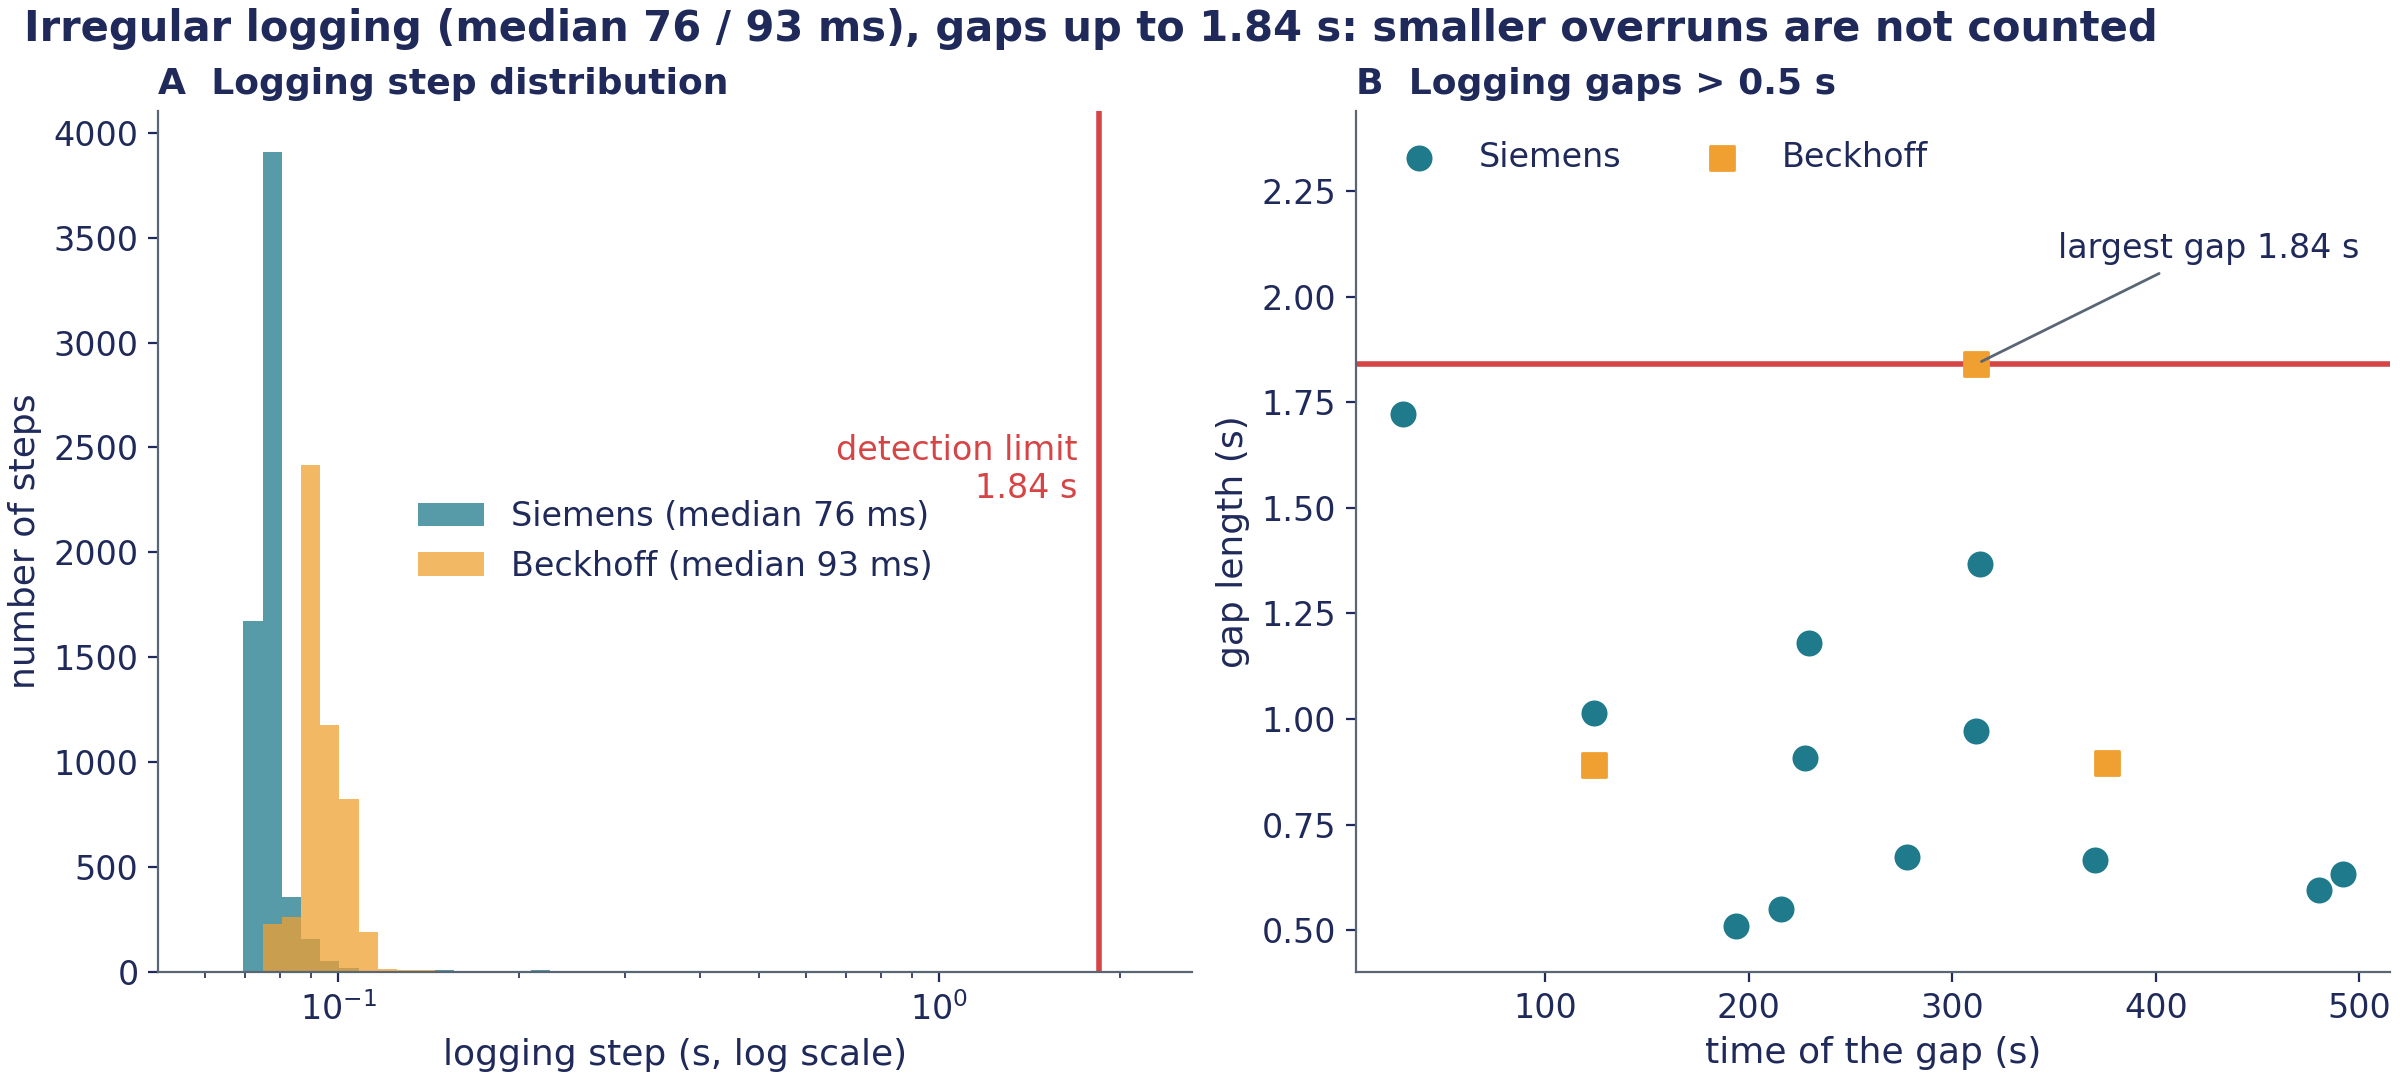

In [42]:
time_base(data, gaps, float(samp["max_step_s"].max()), FIGURES / "time_base.png")
display(Image(filename=str(FIGURES / "time_base.png"), width=900))

**Result (measured):** both PLCs log irregularly (median step about 76 ms and 93 ms). The largest gap, 1.84 s,
is the **detection limit**; the **sync tolerance** is 0.169 s. The largest gaps of the two files coincide: both
loggers paused at the same moment, so the gaps are a property of the logging, not of the machine.

## Part 5 - What do the signals mean? Evidence, not names

*Source: v1 step 2.4 (original code), then the extension.* Only documented meanings are used for interpretation.
For Beckhoff signals the file gives the station only, so the meaning of a Beckhoff signal is a **reading of its
name** and is marked as such.

In [43]:
sie_doc = pd.read_excel(cfg["paths"]["variable_file"], sheet_name="Siemens")
bec_doc = pd.read_excel(cfg["paths"]["variable_file"], sheet_name="Beckhoff")
SIE_DOC = sie_doc.set_index("Variablenname")
BEC_STATION = bec_doc.set_index("Variablenname / Beschreibung")["Station"]

In [44]:
USED_SIEMENS = ["A201.0", "M0.3", "AW256", "E200.0",
                "A1.0", "A0.7", "A1.7", "E1.0", "MD28", "MW32"]
print("Siemens signals used for interpretation (variable file):")
print(SIE_DOC.loc[USED_SIEMENS, ["Station", "Kommentar"]].to_string())

USED_BECKHOFF = ["VG.safeCurtainShort", "Visual.start", "Visual.Stoplight",
                 "WH.desiredPalletX", "WH.desiredPalletY",
                 "WH.I2_Light_barrier_inside", "WH.I3_Light_barrier_outside",
                 "WH.B1_encoder_horizontal_impuls1",
                 "WH.B2_encoder_horizontal_impuls2"]
print("\nBeckhoff sheet columns:", bec_doc.columns.tolist())
print("Beckhoff signals used (only the station is documented):")
print(BEC_STATION.loc[USED_BECKHOFF].to_string())

Siemens signals used for interpretation (variable file):
                        Station                            Kommentar
Variablenname                                                       
A201.0                 Beckhoff  Safetydata from curtain to beckhoff
M0.3             Balluff safety                     1 segment red ON
AW256            Balluff safety        data word that controls light
E200.0                 Beckhoff                Reset button from HMI
A1.0           Drilling station                    drill on (output)
A0.7           Drilling station                          conveyor on
A1.7           Drilling station              Suction on/off (output)
E1.0           Drilling station   lightbarrier in small belt (input)
MD28           Drilling station              Drilling time in second
MW32           Drilling station                   not in Time format

Beckhoff sheet columns: ['Variablenname / Beschreibung', 'Station']
Beckhoff signals used (only the station is doc

`build_dictionary` gives every signal a role (command = actuator output, sensor, state, parameter, interface,
unused) and records whether its reading is *documented*, *measured*, a *name reading* or *unknown*.

**Signal dictionary**

- `INTERPRETATIONS`: Signal readings the analysis relies on, each labelled documented / measured / name reading.
- `_siemens_role`: Role of a Siemens signal from its address and documentation.
- `_beckhoff_role`: Role of a Beckhoff signal from its name (IEC Q = output, I = input).
- `_behaviour`: Observed behaviour of one signal: values, changes, constant or not.
- `build_dictionary`: Signal dictionary: role, documentation, behaviour and evidence status of every signal.

In [45]:
# Interpretations that the analysis relies on, or that are easy to misread
# from the signal names. Each "measured" claim is shown in notebook 02 and listed in docs/methodology.md.
INTERPRETATIONS: dict[str, tuple[str, str]] = {
    # --- Siemens: safety / stop evidence -----------------------------------
    "A201.0": ("Safety light-curtain status sent to Beckhoff; LOW = protective stop. "
               "Its 7 edges reappear in VG.safeCurtainShort (clock check).", "documented"),
    "M0.3": ("Signal lamp 'red' segment; ON exactly while A201.0 is LOW.", "measured"),
    "E200.0": ("HMI reset button; every curtain stop ends with a press.", "documented"),
    "AW256": ("Data word that drives the Balluff signal lamp. Changes at every oven "
              "blink sequence (normal operation) and during stops. NOT a fault or "
              "motion signal.", "documented"),
    "MW26": ("Documented as 'oven time x 2', but every logged value is a combination "
             "of single bits (0x4000..0xB000) and bit 0x2000 is set exactly during the "
             "curtain stops. Behaves as a status bit-field here; not used as a "
             "process parameter.", "measured"),
    "MD28": ("Documented 'drilling time'. Changes only for the one long drill run "
             "(385.07-390.06 s) and back. Units/encoding not verifiable; not used "
             "as commanded-dwell evidence.", "measured"),
    "MW32": ("Documented 'not in time format'. Same change window as MD28. Read "
             "byte-swapped the normal value is 1000 (would match a 1 s drill time) - "
             "hypothesis only.", "measured"),
    "MW22": ("Drilling-station cycle register. Repeats 1 -> 2|3 -> 0 -> 1 once per "
             "part. State 2|3 lasts 7.4-7.5 s and covers the oven/burn phase; state 0 "
             "~1.2 s; state 1 is the variable remainder (transfer, drill, waiting).",
             "measured"),
    "MW20": ("Counted oven-light blinks (0-2) during each oven run.", "documented"),
    "I200.7": ("Sheet says 'Not used' but ON exactly during the first curtain stop.",
               "measured"),
    "M0.1": ("Sheet says 'Not used' but ON exactly during the second curtain stop.",
             "measured"),
    "M24.4": ("Sheet says 'Not used' but ON during start-up and inside the third "
              "curtain stop.", "measured"),
    "A1.0": ("Drill motor. Normal ON time 0.94-1.05 s.", "documented"),
    "M6.4": ("Keeps drill on / drill timer running (documented); tracks A1.0.",
             "documented"),
    "A0.7": ("Small conveyor of the drilling station; carries the part to light "
             "barrier E1.0 and on to the sorting station.", "documented"),
    "E1.0": ("Light barrier on the small conveyor; LOW while a part is in the beam.",
             "documented"),
    "A0.0": ("Long conveyor of the sorting station.", "documented"),
    # --- Beckhoff ---------------------------------------------------------
    "VG.safeCurtainShort": ("Receives A201.0 from Siemens (same edges within 0.09 s).",
                            "measured"),
    "Visual.start": ("HMI run state; LOW once (468.5-473.5 s) = HMI stop.", "name reading"),
    "Visual.Stoplight": ("HMI stop lamp; HIGH exactly while Visual.start is LOW.",
                         "measured"),
    "WH.desiredPalletX": ("Requested rack column of the next pallet; a change starts a "
                          "pallet cycle.", "name reading"),
    "WH.desiredPalletY": ("Requested rack row of the next pallet.", "name reading"),
    "WH.isEmpty": ("Pallet on the belt is empty: set during robot pick 1, cleared at the end of "
                   "robot put-down 2. Start-up cycle: cleared at the next pallet request (no part "
                   "to return). Final cycle: set from the request on (an empty pallet is fetched).",
                   "measured"),
    "WH.Q1_beltForward": ("Warehouse belt outwards; runs until the pallet reaches a light "
                          "barrier.", "measured"),
    "WH.Q2_beltBackward": ("Warehouse belt inwards; runs until the pallet reaches a light "
                           "barrier.", "measured"),
    "WH.Q3_horRack": ("Horizontal axis towards rack: request (stays ON while the motor "
                      "output of the pair is OFF during stops).", "measured"),
    "WH.Q3_horizontal_towards_rack": ("Horizontal axis towards rack: motor output "
                                      "(encoder moves only while it is ON).", "measured"),
    "WH.B1_encoder_horizontal_impuls1": ("Horizontal-axis encoder; pulses while the axis "
                                         "moves. Pulse counts are unreliable at ~11 Hz "
                                         "logging; only presence/absence is used.",
                                         "measured"),
    "VG.Q7_compressorON": ("Robot vacuum compressor; ON for one pick-and-place move. "
                           "Two moves per pallet cycle.", "measured"),
}


def _siemens_role(name: str, dtype: str, desc: str) -> tuple[str, str]:
    d = str(desc).strip().lower()
    if d == "not used":
        return "Unused or unknown", "sheet says 'Not used'"
    if name.startswith(("A200", "A201")):
        return "Interface", "A-output with station 'Beckhoff' (data to Beckhoff)"
    if name.startswith("AW"):
        return "Command", "output word (indicator lamp)"
    if name.startswith("A"):
        return "Command", "S7 output (A = Ausgang)"
    if name.startswith(("E200", "EW256", "EW258")):
        return "Interface", "input from the Beckhoff HMI"
    if name.startswith(("E", "I", "EW")):
        return "Sensor", "S7 input (E = Eingang)"
    if name == "MW16":
        return "Sensor", "analog colour-sensor value copied to memory"
    if name in ("MW26", "MD28", "MW32"):
        return "Parameter", "documented time/scaling value"
    if name.startswith(("MW", "MD", "C")):
        return "State", "memory word / counter"
    if name.startswith("M"):
        return "State", "S7 memory bit (M = Merker)"
    return "Unused or unknown", "no rule"


def _beckhoff_role(name: str) -> tuple[str, str]:
    if ".Q" in name:
        return "Command", "IEC 61131-3 output (Q)"
    if re.search(r"\.(I\d|B\d|A\d)", name):
        return "Sensor", "input (I), encoder (B) or trail sensor (A)"
    if "safeCurtain" in name:
        return "Interface", "safety data received from Siemens"
    if "desiredPallet" in name:
        return "Parameter", "requested rack position"
    if name.startswith("Visual."):
        return "State", "HMI state (station Visualization)"
    if name in ("WH.isEmpty", "VG.atHome", "VG.error_robot"):
        return "State", "status flag"
    return "Unused or unknown", "no rule"


def _behaviour(series: pd.Series, t: np.ndarray) -> dict:
    v = series.to_numpy()
    changes = np.flatnonzero(v[1:] != v[:-1]) + 1
    out = {
        "n_changes": int(len(changes)),
        "constant": bool(len(changes) == 0),
        "first_change_s": float(t[changes[0]]) if len(changes) else np.nan,
        "last_change_s": float(t[changes[-1]]) if len(changes) else np.nan,
        "n_distinct": int(pd.Series(v).nunique()),
        "frac_true": float(v.mean()) if series.dtype == bool else np.nan,
        "min_value": float(np.min(v.astype(float))),
        "max_value": float(np.max(v.astype(float))),
    }
    if series.dtype == bool and len(changes):
        e = t[changes]
        out["shortest_period_s"] = float(np.diff(e).min()) if len(e) > 1 else np.nan
    else:
        out["shortest_period_s"] = np.nan
    return out


def build_dictionary(data: dict) -> pd.DataFrame:
    rows = []
    sie_doc = data["doc"]["Siemens"].set_index("signal")
    bec_doc = data["doc"]["Beckhoff"].set_index("signal")
    for plc, doc in (("Siemens", sie_doc), ("Beckhoff", bec_doc)):
        d = data[plc]
        t = d.frame["t"].to_numpy()
        for sig in d.signals:
            meta = doc.loc[sig] if sig in doc.index else None
            in_doc = meta is not None
            if plc == "Siemens":
                dtype = meta["data_type"] if in_doc else ""
                desc = meta["description"] if in_doc else ""
                role, basis = _siemens_role(sig, dtype, desc)
                symbol = meta["symbol"] if in_doc else ""
            else:
                dtype = str(d.frame[sig].dtype)
                desc = ""
                symbol = ""
                role, basis = _beckhoff_role(sig)
            beh = _behaviour(d.frame[sig], t)
            interp, status = INTERPRETATIONS.get(sig, ("", ""))
            if not interp:
                if plc == "Siemens" and desc and str(desc).strip().lower() != "not used":
                    interp, status = str(desc).strip(), "documented"
                elif plc == "Beckhoff":
                    interp, status = "meaning from the signal name only", "name reading"
                else:
                    interp, status = "", "unknown"
            if beh["constant"]:
                note = "constant over the whole recording; carries no information here"
            elif role == "Unused or unknown":
                note = "documented as unused but changes; treated as unknown"
            else:
                note = ""
            rows.append({
                "plc": plc, "signal": sig, "in_dictionary": in_doc,
                "station": meta["station"] if in_doc else "",
                "station_raw": meta["station_raw"] if in_doc else "",
                "data_type": dtype, "description": desc, "symbol": symbol,
                "role": role, "role_basis": basis, **beh,
                "interpretation": interp, "evidence_status": status, "note": note,
            })
    return pd.DataFrame(rows)

In [46]:
dictionary = build_dictionary(data)
print(dictionary.groupby(["plc", "role"]).size().unstack(fill_value=0))
dictionary[dictionary["signal"].isin(["A201.0", "E200.0", "AW256", "MW22", "MW26", "WH.Q1_beltForward"])][
    ["plc", "signal", "station", "description", "role", "interpretation", "evidence_status"]]

role      Command  Interface  Parameter  Sensor  State  Unused or unknown
plc                                                                      
Beckhoff       22          2          2      21      5                  1
Siemens        22         12          3      17     74                 14


,plc,signal,station,description,role,interpretation,evidence_status
73,Siemens,MW22,Drilling station,Value that tells which cycle is going on,State,Drilling-station cycle register. Repeats 1 -> ...,measured
103,Siemens,A201.0,Beckhoff,Safetydata from curtain to beckhoff,Interface,Safety light-curtain status sent to Beckhoff; ...,documented
109,Siemens,MW26,Drilling station,multiplying Bekchoff value to get real seconds,Parameter,"Documented as 'oven time x 2', but every logge...",measured
116,Siemens,AW256,Balluff safety,data word that controls light,Command,Data word that drives the Balluff signal lamp....,documented
138,Siemens,E200.0,Beckhoff,Reset button from HMI,Interface,HMI reset button; every curtain stop ends with...,documented
179,Beckhoff,WH.Q1_beltForward,Warehouse,,Command,Warehouse belt outwards; runs until the pallet...,measured


**Test a reading before using it.** `AW256` sounds like a status word. If it were a fault indicator it would
change only during faults. Does it change while the line runs normally?

In [47]:
s = data["Siemens"].frame
curtain_low = on_intervals(s["t"], ~s["A201.0"])      # safety-stop windows (curtain interrupted)
v, t = s["AW256"].to_numpy(), s["t"].to_numpy()
changes = t[1:][v[1:] != v[:-1]]
outside = [x for x in changes if not any(a - 0.2 <= x <= b + 0.2 for a, b in curtain_low)]
print(f"AW256 changes {len(changes)} times, {len(outside)} of them outside any stop window")
print("values:", sorted(set(v.tolist())))

AW256 changes 41 times, 18 of them outside any stop window
values: [10.0, 4353.0, 13059.0, 40970.0, 43530.0]


`AW256` is documented as the data word of the signal lamp and changes during normal operation. It is therefore
**not** a fault indicator and never used as loss evidence.

In [48]:
mw26 = s["MW26"].astype(int)
print("MW26 values (hex):", [hex(x) for x in sorted(mw26.unique())])
bit = on_intervals(s["t"], (mw26 & 0x2000) > 0)
print("bit 0x2000 ON intervals:", [(round(a, 2), round(b, 2)) for a, b in bit])
print("curtain LOW intervals    :", [(round(a, 2), round(b, 2)) for a, b in curtain_low])

MW26 values (hex): ['0x4000', '0x8000', '0x8800', '0x9000', '0xa000', '0xa800', '0xb000']
bit 0x2000 ON intervals: [(0.0, 8.85), (255.4, 264.22), (390.06, 400.36), (453.14, 460.74)]
curtain LOW intervals    : [(0.0, 8.85), (255.4, 264.29), (390.06, 400.44), (453.14, 460.74)]


`MW26` is documented as a time value, but it only takes combinations of single bits, and bit 0x2000 is set
exactly while the curtain is interrupted: it behaves as a status bit-field here. Each such reading is listed in `docs/methodology.md`
(section 9).

## Part 6 - Start of production

*Source: v1 step 2.5 - original code.* At the start of the recording the machine is not producing yet. The
production window is defined by a **documented** event: the first press of the HMI reset button (`E200.0`, "Reset
button from HMI"). Everything before it (warehouse homing) is excluded - on the OEE slide start-up losses belong to
Quality, not Performance.

In [49]:
reset_presses = [s for s, _ in on_intervals(sie["t"], sie["E200.0"])]
PRODUCTION_START = reset_presses[0]
homing = on_intervals(bec["t"], bec["WH.Q8_cantBack"])[0]
print("HMI reset button (E200.0) pressed at t =",
      [round(x, 2) for x in reset_presses])
print(f"First cantilever-back command (homing): "
      f"{homing[0]:.2f} to {homing[1]:.2f} s")
print(f"Production window: {PRODUCTION_START:.2f} s to "
      f"{RECORDING_END:.2f} s")

HMI reset button (E200.0) pressed at t = [8.93, 264.29, 400.44, 460.74]
First cantilever-back command (homing): 0.41 to 10.45 s
Production window: 8.93 s to 505.80 s


In [50]:
# hand over to notebook 03: cleaned data, signal dictionary and logging statistics
pulses = shortest_pulses(data)
save_stage("02_data", {"data": {k: (vars(v) if isinstance(v, PLCData) else v) for k, v in data.items()},
                       "dictionary": dictionary, "sampling": samp, "gaps": gaps, "pulses": pulses})

## Summary of data understanding

| Finding (measured or documented) | Consequence |
|---|---|
| Both files end every line with `;` -> one empty column | dropped |
| Last Siemens row: 118 of 142 signals empty (incomplete final write) | excluded; nothing interpolated |
| Logging irregular (median about 76 / 93 ms), gaps up to 1.84 s, largest gaps coincide | detection limit 1.84 s, sync tolerance 0.169 s |
| 8 Beckhoff and 32 Siemens signals are constant; `VG.error_robot` always False | kept; robot errors cannot explain losses |
| Alias pairs such as `WH.Q3_horRack` / `WH.Q3_horizontal_towards_rack` are not identical | both kept; their meaning is measured in notebook 04 |
| `AW256` changes in normal operation; `MW26` is a bit-field | not used as fault or time evidence |
| Production starts at the first HMI reset press | earlier rows are start-up, excluded |

**Next:** notebook 03 prepares the data: common time grid, clock check, stop windows, pallet cycles and the
activation table.